# Machine Learning mini-project

## Understanding Classification and Regression (12 points)

### Classification

Describe a classification problem in chemical, biochemical, or environmental engineering (that is not related to drug discovery, since we've explored that in class). Specify the label of interest, and list at least 2 features that may be relevant for classification. If relevant, provide the units of the variables.

**<font color=blue>0 / 6 points</font>**

Describe the problem:<font color=purple> The nature of soil varies across locations and exhibit different conditions that may be useful for agriculture and landscaping. The problem is a multi-label classification for identifying differetent soil types from the variety of chemical, physical and morphological properties in the soil.
 

Label:<font color=purple> Types of soil: clay, sandy, silty, peaty, chalky, loamy

Features: <font color=purple> pKa, water retention (s), concentration of minerals (ppm)

### Regression

Describe a regression problem in chemical, biochemical, or environmental engineering (that is not related to thermodynamic properties, since we've covered that in class). Specify the label of interest, and list at least 2 features that may be relevant for regression. Also provide the units of the variables, if relevant.

**<font color=blue>0 / 6 points</font>**

Describe the problem: <font color=purple>Sensitivity analysis of wastewater to learn and determine the combination of chemicals that contribute to the formation of toxic substances. Specifically, the formation of trihalomethanes (THM) during water disinfection process is a major concern as these are considered potentially carcinogenic. The regression model for THM concentration with the water quality variables determines a relationship to provide better understanding of the factors affecting their formation and help in decision making.

Label: <font color=purple>THM (trihalomethanes) concentration (ppm)

Features: <font color=purple>pH, temperature (°C), Bromine concentration (ppm), dissolved organic carbon normalized chlorine dose (mg/mg), and contact time (h) 

Reference: https://doi.org/10.1016/j.chemolab.2012.03.014

**Use the cell below to import any libraries you need for this notebook**

In [57]:
import pandas as pd
import numpy as np
import random

import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgba

import rdkit
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem import Draw
from rdkit import DataStructs
from rdkit import RDConfig
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole



import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import sklearn.metrics as metrics

## Part 1: The white wine dataset (45 points)

### Reading and sorting the dataset (5 points)

**<font color=blue>0 / 5 points</font>** Read in the **white** wine quality dataset (find it in the datasets folder on Blackboard), sort it by residual sugar and then by alcohol content, and re-index the rows, so the sorted dataframe goes from 0 to max

In [2]:
WhiteWine = pd.read_csv('winequality-white.csv',delimiter=';', header=0)
WhiteWineSorted = WhiteWine.sort_values(by=['residual sugar', 'alcohol'], ignore_index=True)
WhiteWineSorted

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,8.7,0.240,0.35,0.60,0.042,11.0,71.0,0.99260,3.08,0.38,10.6,5
1,8.7,0.240,0.35,0.60,0.042,11.0,71.0,0.99260,3.08,0.38,10.6,5
2,5.1,0.140,0.25,0.70,0.039,15.0,89.0,0.99190,3.22,0.43,9.2,6
3,5.3,0.210,0.29,0.70,0.028,11.0,66.0,0.99215,3.30,0.40,9.8,5
4,5.2,0.170,0.27,0.70,0.030,11.0,68.0,0.99218,3.30,0.41,9.8,5
...,...,...,...,...,...,...,...,...,...,...,...,...
4893,6.8,0.450,0.28,26.05,0.031,27.0,122.0,1.00295,3.06,0.42,10.6,6
4894,6.8,0.450,0.28,26.05,0.031,27.0,122.0,1.00295,3.06,0.42,10.6,6
4895,7.9,0.330,0.28,31.60,0.053,35.0,176.0,1.01030,3.15,0.38,8.8,6
4896,7.9,0.330,0.28,31.60,0.053,35.0,176.0,1.01030,3.15,0.38,8.8,6


### Categorizing wines and analyzing their properties (10 points)

The LCBO sugar code categorizes wine as dry if it has less than 2% residual sugar, medium (or semi-dry or semi-sweet) if it has between 2 and 7% residual sugar, and sweet if it has >7% residual sugar. 

**<font color=blue>0 / 5 points</font>** Categorize each wine according to its sweetness, and add its category to the dataframe. If you can't figure out how to add the categories to the dataframe, partial credit will be given for creating separate dataframes for each category. Hint: I found [this page](https://datatofish.com/if-condition-in-pandas-dataframe/) to have helpful tips. Finally, what fraction of the wines are in each category?

In [ ]:
pd.set_option('display.max_rows', None)
WhiteWineSorted['sweetness'] = WhiteWineSorted['residual sugar'].apply(lambda x: 'dry' if x < 2 else 
                                                                       ('sweet' if x > 7 else 'semi-sweet'))
WhiteWineSorted

**<font color=blue>0 / 5 points</font>** When wine is fermented, sugar is converted into alcohol. We might therefore expect that high-alcohol wines have less sugar. Do you observe this trend across the whole dataset? What about within each category (for example, among dry wines, do high-alcohol wines have less sugar)? No need to perform regression for this question; plotting the data and describing what you see is sufficient.

In [4]:
fig = go.Figure()


fig.update_layout(template = 'plotly_white')


sweetness = ['dry','semi-sweet','sweet']

sweets = [ WhiteWineSorted[WhiteWineSorted['sweetness'] == x] for x in sweetness ]
colors = ['Red','SlateGrey','Blue']

for x in range(len(colors)):
    fig.add_trace(go.Scatter(
        mode = 'markers',
        x = sweets[x]['alcohol'],
        y = sweets[x]['residual sugar'],
        name = sweetness[x],
        marker = dict(color = x),
        hovertemplate = 'Alcohol Content: %{x:.1f}' +
                        '<br>Residual Sugar: %{y:.1f}',
  
    ))
    
fig.update_layout(
    xaxis_title = 'Alcohol Content',
    yaxis_title = 'Redisual Sugar',
    title = 'Residual Sugar vs Alcohol Content'
)

fig.update_xaxes(zeroline=True, gridcolor = 'lightgray',
                ticks="outside",
                tickfont_size=14,
                tickson="boundaries",
                ticklen=8, showline=True, linewidth=1.5, linecolor='slategray',
                range = [7,15])
fig.update_yaxes(zeroline=True, gridcolor = 'lightgray',
                ticks="outside",
                tickfont_size=14,
                tickson="boundaries",
                ticklen=8, showline=True, linewidth=1.5, linecolor='slategray',
                range = [0,70])

fig.show()
print('There are more wines that are "sweet" on the lower end of the alcohol content compared to the higher end.')
print('This means that sweeter wines are more likely to be less alcoholic.')

There are more wines that are "sweet" on the lower end of the alcohol content compared to the higher end.
This means that sweeter wines are more likely to be less alcoholic.


### Predicting wine quality (30 points)

**<font color=blue>0 / 5 points</font>** Normalize the data to give a mean of zero and a standard deviation of 1. Divide the dataset into training and test sets, with 30% of the data in the test set.

In [16]:
PropertyList = WhiteWine.columns
WhiteWineProps = (WhiteWine[PropertyList] - WhiteWine[PropertyList].mean())/WhiteWine[PropertyList].std()
X_train, X_test, y_train, y_test = train_test_split(WhiteWineProps.drop(columns=['quality']),
                                                    WhiteWineProps['quality'], test_size=0.30, random_state=0)

**<font color=blue>0 / 5 points</font>** Fit a model to predict wine quality using linear regression, and report the RMSE of the training and test sets. Make a parity plot showing the accuracy of your predictions in the training and test sets. (Report quality in original units; minus 1 point if reported in normalized units)

In [17]:
std  = np.std(WhiteWine['quality'])
mean = np.mean(WhiteWine['quality'])

regr = LinearRegression()
regr.fit(X_train,y_train)

pred_train = regr.predict(X_train)
pred_test  = regr.predict(X_test)



# The normalized root mean squared error
print('Normalized training RMSE: %.2f'
      % mean_squared_error(y_train,pred_train))
print('Normalized test RMSE: %.2f'
      % mean_squared_error(y_test,pred_test))

yTrain = [y*std + mean for y in y_train]
yTest  = [y*std + mean for y in y_test ]
pTrain = [y*std + mean for y in pred_train]
pTest  = [y*std + mean for y in pred_test ]


# The actual root mean squared error
print('\nActual training RMSE: %.2f'
      % (mean_squared_error(yTrain,pTrain)))
print('Actual test RMSE: %.2f'
      % (mean_squared_error(yTest,pTest)))


fig = go.Figure()

fig.update_layout(
     template = 'simple_white'
)

fig.add_trace(go.Scatter(
    mode = 'markers',
    x = yTrain,
    y = pTrain,
    name = 'Train',
    marker = dict(color = 'blue'),
    hovertemplate = 'Train <extra></extra>' +
                    '<br>Experimental: %{x:.0f}' +
                    '<br>Predicted: %{y:.2f}',
))

fig.add_trace(go.Scatter(
    mode = 'markers',
    x = yTest,
    y = pTest,
    name = 'Test',
    marker = dict(color = 'red'),
    hovertemplate = 'Test <extra></extra>' +
                    '<br>Experimental: %{x:.0f}' +
                    '<br>Predicted: %{y:.2f}',
))

fig.add_trace(go.Scatter(
    mode = 'lines',
    x = [2.75,9.25],
    y = [2.75,9.25],
    name = 'Line',
    line = dict(color = 'black')
))

fig.update_layout(
    xaxis_title = 'Experimental',
    yaxis_title = 'Predicted',
    title = 'Parity plot of quality'
)

for trace in fig['data']: 
    if(trace['name'] == 'Line'): trace['showlegend'] = False
    
fig.show()

Normalized training RMSE: 0.70
Normalized test RMSE: 0.78

Actual training RMSE: 0.55
Actual test RMSE: 0.61


**<font color=blue>0 / 5 points</font>** Fit a model to predict wine quality using LASSO regression, adjusting the value of alpha until you have 4 nonzero coefficients remaining. Report the normalized RMSE for the test set and the training set.

In [19]:
regr = Lasso(alpha=0.075)
regr.fit(X_train,y_train)

pred_train = regr.predict(X_train)
pred_test  = regr.predict(X_test)

RMSE_train = metrics.mean_squared_error(y_train,pred_train)
RMSE_test  = metrics.mean_squared_error(y_test,pred_test)

print('Coefficients:',regr.coef_)
print('Normalized RMSE for train:',RMSE_train)
print('Normalized RMSE for test:' ,RMSE_test )

Coefficients: [-0.00000000e+00 -1.42565930e-01 -0.00000000e+00  0.00000000e+00
 -4.62549950e-05  3.54520473e-02 -0.00000000e+00 -0.00000000e+00
  0.00000000e+00  0.00000000e+00  3.78925766e-01]
Normalized RMSE for train: 0.7472983300709374
Normalized RMSE for test: 0.8098724297622876


**<font color=blue>0 / 10 points</font>** Fit three models to predict wine quality using LASSO regression, one model for each category of wine (sweet, semi-sweet, dry), and report the RMSE for the training and test set for each category. Are some types of wine easier to predict than other types? Are the same factors important across all categories, or is quality among dry white wines characterized by different features compared to quality among sweet wines?

In [20]:
#alphas = [0.2,0.105,0.05]

sweetProps = [(sweets[x][PropertyList] - sweets[x][PropertyList].mean())/sweets[x][PropertyList].std() for x in range(len(sweets))]
X_trains = [0]*len(sweets)
X_tests  = [0]*len(sweets)
y_trains = [0]*len(sweets)
y_tests  = [0]*len(sweets)
pred_trains = [0]*len(sweets)
pred_tests  = [0]*len(sweets)
for x in range(len(sweets)):
    X_trains[x], X_tests[x], y_trains[x], y_tests[x] = train_test_split(sweetProps[x].drop(columns=['quality']),
                                                        sweetProps[x]['quality'], test_size=0.20, random_state=0)
    regr = Lasso(alpha=0.075)
    #regr = Lasso(alpha=alphas[x])
    regr.fit(X_trains[x],y_trains[x])
    
    pred_trains[x] = regr.predict(X_trains[x])
    pred_tests[x]  = regr.predict(X_tests[x] )
    
    RMSE_train = metrics.mean_squared_error(y_trains[x],pred_trains[x])
    RMSE_test  = metrics.mean_squared_error(y_tests[x],pred_tests[x])
    
    txt = sweetness[x]
    print(txt.capitalize(),'coefficients:',regr.coef_)
    print('Normalized RMSE for train:',RMSE_train)
    print('Normalized RMSE for test:' ,RMSE_test,'\n')

Dry coefficients: [-0.         -0.1514716   0.          0.04397373 -0.          0.08681466
 -0.         -0.18743184  0.06813598  0.09010405  0.17432507]
Normalized RMSE for train: 0.6772762861491801
Normalized RMSE for test: 0.7738837505656887 

Semi-sweet coefficients: [-0.         -0.07512073 -0.          0.         -0.          0.0312678
 -0.         -0.12465404  0.03443903  0.          0.3310068 ]
Normalized RMSE for train: 0.6914217645680845
Normalized RMSE for test: 0.7310923199409942 

Sweet coefficients: [-0.         -0.210939   -0.          0.         -0.00477117 -0.
 -0.         -0.         -0.          0.          0.27116251]
Normalized RMSE for train: 0.820077787587847
Normalized RMSE for test: 0.8030599440592673 



**<font color=blue>0 / 5 points</font>** Display these predictions in two side-by-side parity plots (using matplotlib or plotly; it's your choice). In one parity plot, show the prediction vs. experiment using the whole data set and one set of fitted coefficients, while coloring the points according to their category, and changing the marker style according to test or training set. In the other parity plot, show the prediction vs. experiment using where the predictions come from the three separate models, still coloring the points according to their category, and changing the marker style according to test or training set.

In [21]:
stds  = [np.std(sweets[x]['quality'])  for x in range(len(sweets))]
means = [np.mean(sweets[x]['quality']) for x in range(len(sweets))]

yTrains = [[y*stds[x] + means[x] for y in y_trains[x]] for x in range(len(y_trains))]
yTests  = [[y*stds[x] + means[x] for y in y_tests[x] ] for x in range(len(y_trains)) ]
pTrains = [[y*stds[x] + means[x] for y in pred_trains[x]] for x in range(len(y_trains))]
pTests  = [[y*stds[x] + means[x] for y in pred_tests[x] ] for x in range(len(y_trains)) ]

yTrains_all = [x for y in yTrains for x in y]
yTests_all  = [x for y in yTests  for x in y]
pTrains_all = [x for y in pTrains for x in y]
pTests_all  = [x for y in pTests  for x in y]

In [22]:
from plotly.subplots import make_subplots

fig = make_subplots(rows=1, cols=2,
                    subplot_titles=('Parity Plot of Quality (Full)','Parity Plot of Quality (Separated)'))

fig.update_layout(
     template = 'simple_white'
)

fig.add_trace(
    go.Scatter(
        mode = 'markers',
        x = yTrain,
        y = pTrain,
        name = 'Train',
        marker = dict(color = 'blue'),
        hovertemplate = 'Experimental: %{x:.0f}' +
                    '<br>Predicted: %{y:.2f}',
    ),
    row = 1,
    col = 1
)

fig.add_trace(
    go.Scatter(
        mode = 'markers',
        x = yTest,
        y = pTest,
        name = 'Test',
        marker = dict(color = 'red'),
        hovertemplate = 'Experimental: %{x:.0f}' +
                    '<br>Predicted: %{y:.2f}',
    ),
    row = 1,
    col = 1
)

fig.add_trace(
    go.Scatter(
        mode = 'lines',
        x = [2.75,9.25],
        y = [2.75,9.25],
        name = 'Line',
        line = dict(color = 'black')
    ),
    row = 1,
    col = 1
)

fig.add_trace(
    go.Scatter(
        mode = 'markers',
        x = yTrains_all,
        y = pTrains_all,
        name = 'Trains',
        marker = dict(color = 'blue'),
        hovertemplate = 'Experimental: %{x:.0f}' +
                    '<br>Predicted: %{y:.2f}',
    ),
    row = 1,
    col = 2
)

fig.add_trace(
    go.Scatter(
        mode = 'markers',
        x = yTests_all,
        y = pTests_all,
        name = 'Tests',
        marker = dict(color = 'red'),
        hovertemplate = 'Experimental: %{x:.0f}' +
                    '<br>Predicted: %{y:.2f}',
    ),
    row = 1,
    col = 2
)

fig.add_trace(
    go.Scatter(
        mode = 'lines',
        x = [2.75,9.25],
        y = [2.75,9.25],
        name = 'Line',
        line = dict(color = 'black')
    ),
    row = 1,
    col = 2
)

fig.update_xaxes(title_text="Experimental", tickmode = 'linear', tick0 = 3, dtick = 1, row=1, col=1)
fig.update_xaxes(title_text="Experimental", tickmode = 'linear', tick0 = 3, dtick = 1, row=1, col=2)
fig.update_yaxes(title_text="Predicted", row=1, col=1)
fig.update_yaxes(title_text="Predicted", row=1, col=2)

for trace in fig['data']: 
    if(trace['name'] == 'Line'): trace['showlegend'] = False
    elif(trace['name'] == 'Trains'): trace['showlegend'] = False
    elif(trace['name'] == 'Tests'): trace['showlegend'] = False

#fig2['layout']['xaxis']['title']='Experiment'
#fig2['layout']['yaxis']['title']='Prediction'

#for trace in fig['data']: 
#    trace['showlegend'] = False

#for trace in fig2['data']: 
#    trace['showlegend'] = False
fig.show()

## Part 2: EFGR Inhibitor Classification (43 points)

### Loading and visualizing molecules (3 points)

**<font color=blue>0 / 3 points</font>** Load the .csv files for the active and inactive EFGR inhibitors into a DataFrame, and create lists of molecule objects for each. Display in a grid 5 molecules from each set. 

In [23]:
df_activeEFGR = pd.read_csv('Chembl_EGFR_actives_ML.csv',delimiter=',', header=0)
df_inactiveEFGR = pd.read_csv('Chembl_EGFR_inactives_ML.csv',delimiter=',', header=0)

activeSMILES = df_activeEFGR['canonical_smiles'].tolist()
inactiveSMILES = df_inactiveEFGR['canonical_smiles'].tolist()

activeMols = [Chem.MolFromSmiles(i) for i in activeSMILES]
inactiveMols = [Chem.MolFromSmiles(i) for i in inactiveSMILES]

numMols = 5 

The five active molecules are:



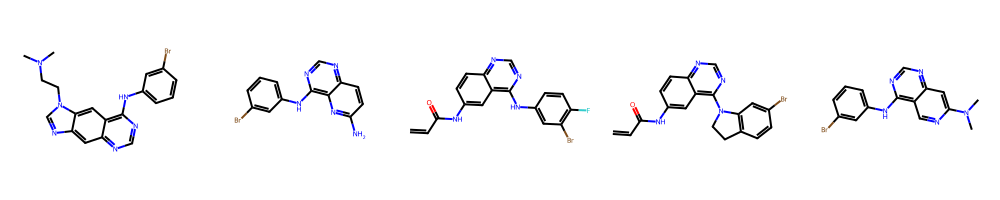

In [24]:
print("The five active molecules are:\n")
Draw.MolsToGridImage((random.sample(activeMols,numMols)), molsPerRow=5, useSVG=True)

The five inactive molecules are:



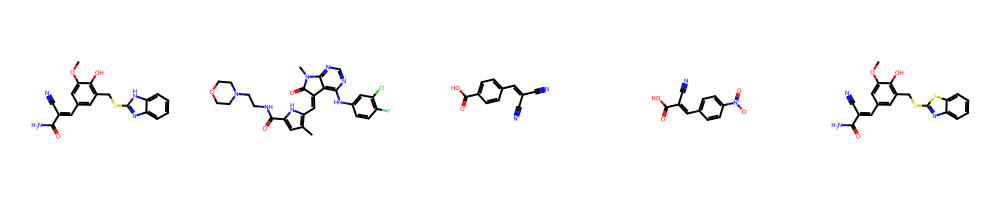

In [25]:
print("The five inactive molecules are:\n")
Draw.MolsToGridImage((random.sample(inactiveMols,numMols)), molsPerRow=5, useSVG=True)

### Classification using global descriptors (10 points)

**<font color=blue>0 / 5 points</font>** Use RDKit to calculate the values of at least 5 global descriptors (such as heavy atom count, LogP, etc.). Add these values to the DataFrame from the previous problem. 

In [26]:
#Exact molecular weight
activeExactMolWt = [Descriptors.ExactMolWt(x) for x in activeMols]
inactiveExactMolWt = [Descriptors.ExactMolWt(x) for x in inactiveMols]

df_activeEFGR['Exact mol weight'] = activeExactMolWt
df_inactiveEFGR['Exact mol weight'] = inactiveExactMolWt


#Heavy atom count
activeHeavyAtomCount = [Descriptors.HeavyAtomCount(x) for x in activeMols]
inactiveHeavyAtomCount = [Descriptors.HeavyAtomCount(x) for x in inactiveMols]

df_activeEFGR['Heavy atoms'] = activeHeavyAtomCount
df_inactiveEFGR['Heavy atoms'] = inactiveHeavyAtomCount


#Number of valence electrons 
activeNumValenceElectrons = [Descriptors.NumValenceElectrons(x) for x in activeMols]
inactiveNumValenceElectrons = [Descriptors.NumValenceElectrons(x) for x in inactiveMols]

df_activeEFGR['Valence electrons'] = activeNumValenceElectrons
df_inactiveEFGR['Valence electrons'] = inactiveNumValenceElectrons


#Number of radical electrons
activeNumRadicalElectrons = [Descriptors.NumRadicalElectrons(x) for x in activeMols]
inactiveNumRadicalElectrons = [Descriptors.NumRadicalElectrons(x) for x in inactiveMols]

df_activeEFGR['Radical electrons'] = activeNumRadicalElectrons
df_inactiveEFGR['Radical electrons'] = inactiveNumRadicalElectrons


#Octanol-water partition coefficient
activeMolLogP = [Descriptors.MolLogP(x) for x in activeMols]
inactiveMolLogP = [Descriptors.MolLogP(x) for x in inactiveMols]

df_activeEFGR['Kow'] = activeMolLogP
df_inactiveEFGR['Kow'] = inactiveMolLogP

**<font color=blue>0 / 5 points</font>** Using these global descriptors as your features, fit a classification model to predict activity. Put 20% of the molecules in the test set (when you do this, please use `train_test_split` and set random=0), and report the accuracy of the model. How accurate is this model on the training set? On the test set?

In [27]:
#Combine Features
activeFeatures = df_activeEFGR.drop(columns=['canonical_smiles','molecule_chembl_id'])
inactiveFeatures = df_inactiveEFGR.drop(columns=['canonical_smiles','molecule_chembl_id'])
Features = [activeFeatures, inactiveFeatures]
X = pd.concat(Features) #Concatenate features


#Assign classes to each molecule
act_y = np.ones(len(activeFeatures)) #ones for active
inact_y = np.zeros(len(inactiveFeatures)) #zeroes for inactive
y = np.concatenate([act_y, inact_y]) # Classifier



#Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0)


#Train the model
clf = LogisticRegression(random_state=0).fit(X_train,y_train)
print("The parameters are: ", clf.coef_)

y_train_pred = clf.predict(X_train)
y_train_prob = clf.predict_proba(X_train)
scoreTrain = clf.score(X_train,y_train)
print("The score for training set is: ", scoreTrain)

#Test performance of the model
y_test_pred = clf.predict(X_test)
y_test_prob = clf.predict_proba(X_test)
scoreTest = clf.score(X_test,y_test)
print("The score for test set is: ", scoreTest)


accuracy = metrics.accuracy_score(y_test,y_test_pred)
print("The accuracy for the model is: ", accuracy)

# The confusion matrix shows false positives and false negatives
print("Confusion matrix: ")
print(metrics.confusion_matrix(y_test,y_test_pred))

The parameters are:  [[ 0.02687521 -0.30191406 -0.019344    0.          0.17398747]]
The score for training set is:  0.6625
The score for test set is:  0.75
The accuracy for the model is:  0.75
Confusion matrix: 
[[17  5]
 [ 5 13]]


### Classification using Morgan fingerprints (30 points)

**<font color=blue>0 / 5 points</font>** Calculate Morgan fingerprints of radius 2 for each molecule, and fit a classification model using the fingerprints as your features (put 20% of the molecules in the test set). Report the accuracy of the model on the training set and test set. (This question closely resembles what we did in Lecture 21 Notebook)

In [47]:
#Morgan fingerprints with radius 2 (MFP2)

morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

#Fingerprint each molecule and keep its bit info (bit -> (atom, radius))
#bit_info: merged over the whole set; bit_info_list: one dict per molecule (needed for drawing substructures)
def morgan_fps(mols, bit_info, bit_info_list):
    fps = []
    for mol in mols:
        ao = rdFingerprintGenerator.AdditionalOutput()
        ao.AllocateBitInfoMap()
        fps.append(morgan_gen.GetFingerprint(mol, additionalOutput=ao))
        bit_info.update(ao.GetBitInfoMap())
        bit_info_list.append(ao.GetBitInfoMap())
    return fps

bi_active = {}
bi_inactive = {}
bi_activeList = []
bi_inactiveList = []
morgan_active_fp = morgan_fps(activeMols, bi_active, bi_activeList)
morgan_inactive_fp = morgan_fps(inactiveMols, bi_inactive, bi_inactiveList)


# activeFps = rdFingerprintGenerator.GetFPs(activeMols)
# inactiveFps = rdFingerprintGenerator.GetFPs(inactiveMols)
Xfps = morgan_active_fp + morgan_inactive_fp #Concatenate fingerprints

#Assign classes to each molecule
activeY = np.ones(len(morgan_active_fp)) #ones for active
inactiveY = np.zeros(len(morgan_inactive_fp)) #zeroes for inactive
yFPs = np.concatenate([activeY, inactiveY]) # Classifier


#Split data in train and test set
X_trainFPs, X_testFPs, y_trainFPs, y_testFPs = train_test_split(Xfps, yFPs, test_size=0.20, random_state=0)
clf = LogisticRegression(random_state=0).fit(X_trainFPs,y_trainFPs)
#print("The parameters are: \n", list(*clf.coef_))


#Train the model
y_train_predFPs = clf.predict(X_trainFPs)
y_train_probFPs = clf.predict_proba(X_trainFPs)
scoreTrainFPs = clf.score(X_trainFPs,y_trainFPs)
print("The score for training set is: ", scoreTrainFPs)

#Test performance of the model
y_test_predFPs = clf.predict(X_testFPs)
y_test_probFPs = clf.predict_proba(X_testFPs)
scoreTestFPs = clf.score(X_testFPs,y_testFPs)
print("The score for test set is: ", scoreTestFPs)


accuracyFPs = metrics.accuracy_score(y_testFPs,y_test_predFPs)
print("The accuracy for the model is: ", accuracyFPs)

# The confusion matrix shows false positives and false negatives
print("Confusion matrix: ")
print(metrics.confusion_matrix(y_testFPs,y_test_predFPs))

The score for training set is:  0.99375
The score for test set is:  0.925
The accuracy for the model is:  0.925
Confusion matrix: 
[[20  2]
 [ 1 17]]


**<font color=blue> 0 / 10 points </font>** Examine the Tanimoto similarity of the active and inactive molecules to each of the 5 FDA-approved molecules using the fingerprints. Think of a way to visualize this, and share your findings.

In [ ]:
df_FDA = pd.read_csv('EGFR-FDA.csv', delimiter=',', names=['Smiles', 'Name'], header=None)
FDAsmiles = df_FDA['Smiles'].tolist()

FDAmols = [Chem.MolFromSmiles(i) for i in FDAsmiles]
FDAfps = rdFingerprintGenerator.GetFPs(FDAmols)


activeTanimoto = [[] for x in range(len(FDAfps))]
inactiveTanimoto = [[] for x in range(len(FDAfps))]

for i in range(len(FDAfps)):
    for fp in morgan_active_fp:
        activeTanimoto[i].append(DataStructs.TanimotoSimilarity(FDAfps[i],fp))
    for fp in morgan_inactive_fp:
        inactiveTanimoto[i].append(DataStructs.TanimotoSimilarity(FDAfps[i],fp))

DrugNames=[x for x in df_FDA['Name']]

#Converting arrays to dataframe
df_inactiveTanimoto = pd.DataFrame({i: j for i,j in zip(DrugNames, inactiveTanimoto)})
df_activeTanimoto = pd.DataFrame({i: j for i,j in zip(DrugNames, activeTanimoto)})

#Combining dataframe for active and inactive
df_inactiveTanimoto['activity'] = 'inactive'
df_activeTanimoto['activity'] = 'active'
dfdata = pd.concat([df_inactiveTanimoto, df_activeTanimoto], axis=0, ignore_index=True)

#Reshaping dataframe for ridgeplot
df = dfdata.melt(id_vars='activity', value_vars=DrugNames,
            var_name = "FDA drug", value_name = "similarity")
df

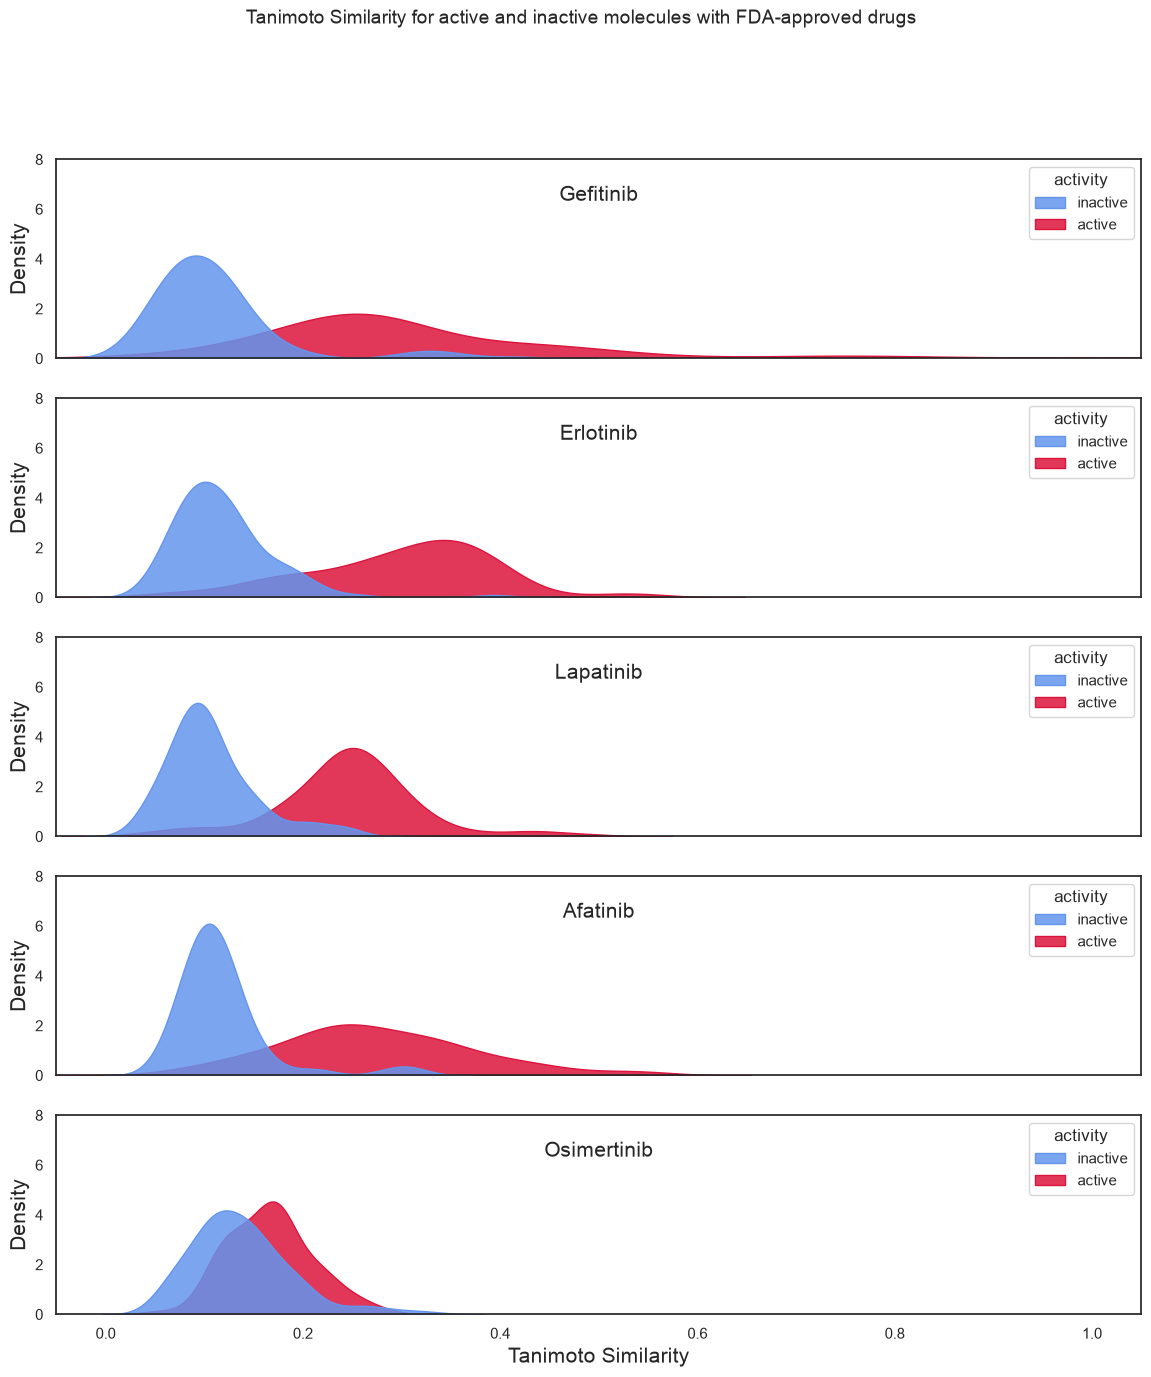

In [ ]:

color_dict = {'active': to_rgba('crimson', 1),
              'inactive': to_rgba('cornflowerblue', 1)}

sns.set_theme(style="white")

fig, axes = plt.subplots(5, 1, sharex=True, figsize=(14,15))
fig.suptitle('Tanimoto Similarity for active and inactive molecules with FDA-approved drugs', fontsize = 14)


for i, drug in enumerate(DrugNames):
    sns.kdeplot(ax=axes[i], data=dfdata, x=str(drug), hue = 'activity',fill=True, alpha=0.85, legend = True, 
                palette=color_dict, multiple='layer')
    axes[i].set_title(str(drug), loc = 'center', y = 0.75, fontsize = 15)
    axes[i].set_xlabel('Tanimoto Similarity', fontsize = 15)
    axes[i].set_xlim(left = -0.05, right =1.05)
    axes[i].set_ylabel('Density', fontsize = 15)
    axes[i].set_ylim(bottom = 0, top =8)

**<font color=blue> 0 / 10 points </font>** Take a look at the classification coefficients. Which molecular fingerprint features have the most positive weights, and which have the most negative weights? How many molecules in the active set and the inactive set have the feature with the highest positive weight? How many molecules in the active set and inactive set have the feature with the lowest negative weight? 

In [50]:
coeff = list(*clf.coef_)
#print("The parameters are: \n", coeff)
import plotly.graph_objects as go

fig = go.Figure()

# positives = [x for x in coeff if x > 0]
# negatives = [x for x in coeff if x < 0]


fig.add_trace(go.Scatter(
        mode = 'markers',
        x = np.arange(0,len(coeff)),
        y = coeff,
        showlegend = False,
        marker = dict(color = 'cornflowerblue'),
        hovertemplate = '<extra></extra>' 
                        +'Morgan FPs: %{x}' +
                        '<br>Coefficient: %{y:.3f}'
    
    ))


fig.update_layout(
    template = 'simple_white',
    xaxis_title = 'Morgan fingerprints',
    yaxis_title = 'Classification coefficients',
    title = 'Classification coefficient vs Morgan fingerprint'
)

fig.show()


M_fps = np.arange(0,len(coeff))
class_coeff = np.array(coeff)
figdict = dict(zip(M_fps,class_coeff)) 


max_weight = max(figdict, key=figdict.get)
print("The molecular fingerprint with the most positive weight is:", max_weight)

min_weight = min(figdict, key=figdict.get)
print("The molecular fingerprint with the most negative weight is:", min_weight)

positiveActive   = [int(x.ToBitString()[max_weight]) for x in morgan_active_fp]
positiveInactive = [int(x.ToBitString()[max_weight]) for x in morgan_inactive_fp]
negativeActive   = [int(x.ToBitString()[min_weight]) for x in morgan_active_fp]
negativeInactive = [int(x.ToBitString()[min_weight]) for x in morgan_inactive_fp]
print('\nNumber of active molecules with the most positive weight:',sum(positiveActive))
print('Number of inactive molecules with the most positive weight:',sum(positiveInactive))
print('Number of active molecules with the most negative weight:'  ,sum(negativeActive))
print('Number of inactive molecules with the most negative weight:',sum(negativeInactive))

The molecular fingerprint with the most positive weight is: 1226
The molecular fingerprint with the most negative weight is: 1410

Number of active molecules with the most positive weight: 75
Number of inactive molecules with the most positive weight: 1
Number of active molecules with the most negative weight: 2
Number of inactive molecules with the most negative weight: 7


The first active molecule with the most positive weight:


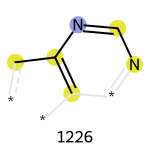

**<font color=blue> 0 / 5 points </font>** For the feature with the largest positive weight, find a molecule in the active set with that fragment, and visualize the fingerprint fragment. For the feature with the most negative weight, find a molecule in the inactive set with that fragment, and visualize the fingerprint fragment.

The first active molecule with the most positive weight:


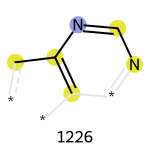

In [54]:
print('The first active molecule with the most positive weight:')
posActiveEg_mol = activeMols[positiveActive.index(1)] #the mol object
posActiveEg_bi = bi_activeList[positiveActive.index(1)] #the bit information

#posActiveEg_fp = rdMolDescriptors.GetMorganFingerprintAsBitVect(posActiveEg_mol, radius=2, bitInfo=bi_Act)

Draw.DrawMorganBit(posActiveEg_mol,max_weight,posActiveEg_bi, legend = str(max_weight))

The first inactive molecule with the most negative weight:


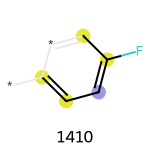

In [55]:
print('The first inactive molecule with the most negative weight:')

negInactiveEg_mol = inactiveMols[negativeInactive.index(1)] #the mol object
negInactiveEg_bi = bi_inactiveList[negativeInactive.index(1)] #the bit information

# negInactiveEg_fp = rdMolDescriptors.GetMorganFingerprintAsBitVect(negInactiveEg_mol, radius=2, bitInfo=bi_Inact)
# tpls_inact = [(negInactiveEg,x,bi_Inact) for x in negInactiveEg_fp.GetOnBits()]

Draw.DrawMorganBit(negInactiveEg_mol, min_weight, negInactiveEg_bi, legend = str(min_weight))